# Visualizing Variance

Statistics becomes much easier to understand when we can see it.

In this notebook, we'll build a series of visualizations that explain **why variance exists**, what it measures, and how to interpret it.

These figures are the same ones used throughout the accompanying Medium article.

### Same Mean 
### Different Variance

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
dataset_1 = [68,69,70,71,72]
dataset_2 = [40,60,70,80,100]

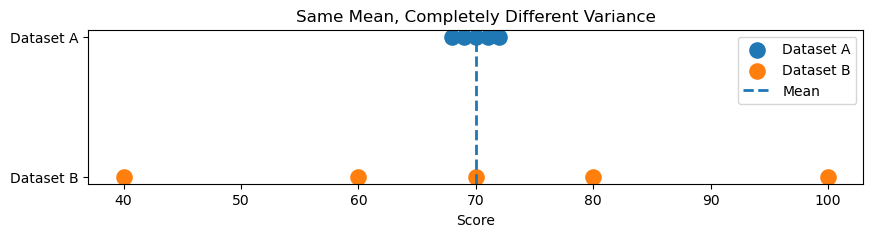

In [4]:
fig, ax = plt.subplots(figsize=(10, 2)) #plt.subplots creates a figure and axes and the width is 10 and height is 2

ax.scatter(dataset_1,#x-ccordinate
           [1] * len(dataset_1),#y-coordinate
           s=120,
           label="Dataset A")

ax.scatter(dataset_2,
           [0] * len(dataset_2),
           s=120, #controls the marker size
           label="Dataset B")

ax.axvline(70, #axvline means axis vertical line and we draw it at mean
           linestyle="--",
           linewidth=2,
           label="Mean")

ax.set_yticks([0,1])

ax.set_yticklabels(
    ["Dataset B", "Dataset A"]
)

ax.set_xlabel("Score")
ax.set_title("Same Mean, Completely Different Variance")

ax.legend()

plt.savefig(
    "../images/same_mean_different_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Although both datasets have exactly the same mean, their variability is dramatically different.

This is precisely why the mean alone cannot describe a dataset.

Variance captures what the average hides.

# Figure 2 — Distance from the Mean

Variance is built on one simple idea:

> **How far is each observation from the average?**

These distances are called **deviations**.

Let's visualise them.

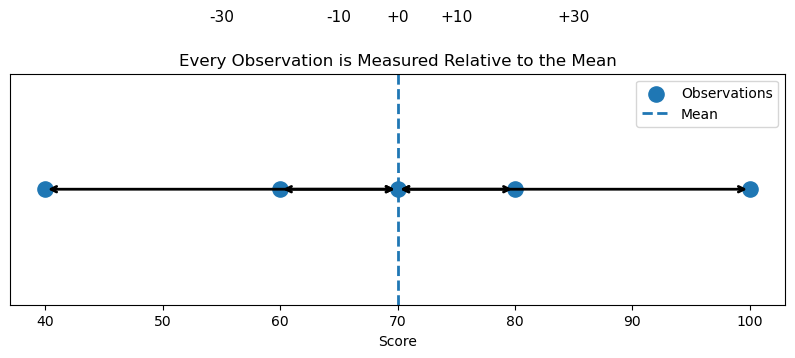

In [5]:
import matplotlib.pyplot as plt

scores = [40,60,70,80,100]
mean = 70

plt.figure(figsize=(10,3))

#Plot Observations
plt.scatter(scores,
            [0] * len(scores),
             s=120,
              zorder=3,
               label="Observations")

#Mean Line
plt.axvline(mean,
            linestyle="--",
            linewidth=2,
            label="Mean")


#Draw Arrows
for score in scores:
    plt.annotate(
        "",#no text with arrow
        xy=(mean, 0),#where arrow ends
        xytext=(score, 0),#where arrow starts
        arrowprops=dict(arrowstyle="<->", lw=2)
    )

    plt.text((score + mean) / 2, #put text halfway the arrow
             0.08, #y-placement of text
             f"{score - mean:+}", #label
             ha="center",
             fontsize=11)
    
plt.yticks([])#remove y axis
plt.xlabel("Score")
plt.title("Every Observation is Measured Relative to the Mean")
plt.legend()

plt.savefig("../images/deviation_from_mean.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

The arrows represent the deviation of each observation from the mean.

Observations to the left of the mean have **negative deviations**.

Observations to the right have **positive deviations**.

If we simply add these numbers together, the positive and negative values cancel each other out.

That's exactly why we needed a better measure of spread.

# Figure 3 — Why Do We Square the Deviations?

Squaring solves two problems at once.

1. Every value becomes positive.
2. Larger deviations become much more important.

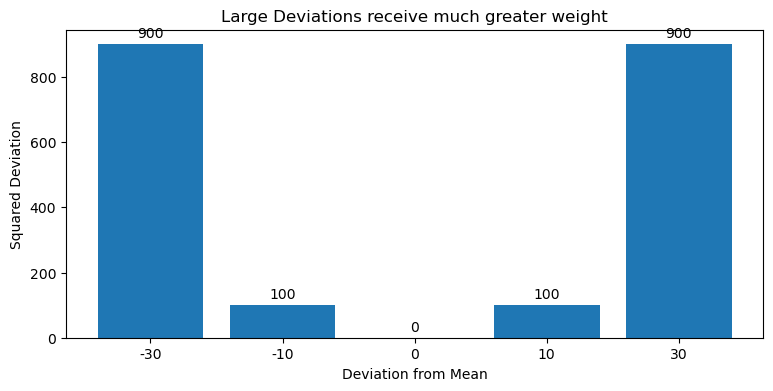

In [ ]:
deviations = [-30,-10,0,10,30]
squared = [d**2 for d in deviations]

plt.figure(figsize=(9,4))

plt.bar(range(len(deviations)), squared) #defining the x axis and y axis

plt.xticks(range(len(deviations)),deviations) #defining the numbers we want to display for x axis

plt.xlabel("Deviation from Mean")

plt.ylabel("Squared Deviation")

plt.title("Large Deviations receive much greater weight")

for i, value in enumerate(squared):#i is the position and value is the actual values of squared
    plt.text(i,#we are writing the bar lables
             value + 20,
             str(value),
             ha="center")

plt.savefig("../images/squared_deviations.png",
            dpi=300,
            bbox_inches="tight")

plt.show()


Notice how the deviations of **±30** become **900**, while deviations of **±10** become only **100**.

Observations that lie far away from the mean contribute much more to the variance.

This is one of the reasons variance is so useful in statistics and machine learning.

/var/folders/ny/102l8bqd52n4j8b25cw9zcvr0000gn/T/ipykernel_3731/1044735165.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


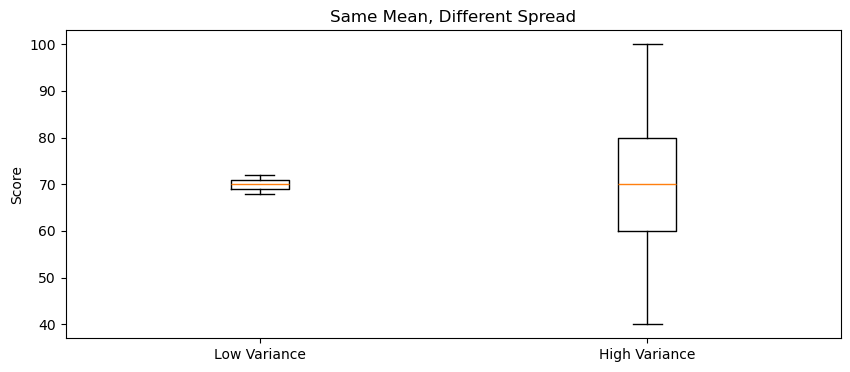

In [ ]:
low_variance = [68,69,70,71,72]
high_variance = [40,60,70,80,100]

fig, ax = plt.subplots(figsize=(10,4))

ax.boxplot(
    [low_variance, high_variance],
    labels=["Low Variance", "High Variance"]
)

ax.set_ylabel("Score")
ax.set_title("Same Mean, Different Spread")

plt.savefig("../images/boxplot_variance.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

Both datasets have exactly the same mean.

Yet one is tightly clustered, while the other is widely spread out.

This is precisely what variance is designed to measure.

# Figure 5 — Population vs Sample

Most real-world datasets are only a sample of a much larger population.

This distinction explains why population variance and sample variance use slightly different formulas.

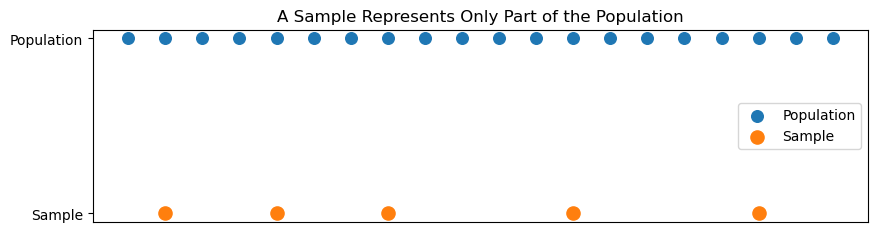

In [8]:
import numpy as np

population = np.arange(1,21)
sample = [2,5,8,13,18]

plt.figure(figsize=(10,2.5))

plt.scatter(population,
            [1] * len(population),
            s=70,
            label="Population")

plt.scatter(sample,
            [0] * len(sample),
            s=90,
            label="Sample")

plt.yticks([0,1],
           ["Sample", "Population"])
plt.xticks([])
plt.title("A Sample Represents Only Part of the Population")

plt.legend()

plt.savefig("../images/population_vs_sample.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

In practice, we rarely observe an entire population.

Instead, we collect a sample and use it to estimate the characteristics of the population.

That's why sample variance includes a small correction (dividing by **n−1** instead of **n**).

# What These Figures Taught Us

Visual intuition often comes before mathematical understanding.

In this notebook, we've seen that:

- Two datasets can share the same mean but have very different variability.
- Variance is built by measuring deviations from the mean.
- Squaring prevents positive and negative deviations from cancelling.
- Large deviations contribute much more than small ones.
- Population and sample variance answer slightly different statistical questions.

These visual ideas form the intuition behind one of the most important concepts in statistics.